In [10]:
from data import load_split, load_movies

train, val, test = load_split("movielens", "dev") 
# train, val, test = load_split("netflix", "dev") 
train.head()

,userId,movieId,rating,timestamp
0,57,3977,0.5,1142398449
1,57,2692,4.0,1142398459
2,57,3052,4.0,1142398483
3,57,2329,4.5,1142398498
4,57,1909,4.5,1142398511


In [11]:
train.shape   

(851711, 4)

In [5]:
train.describe() 

,userId,movieId,rating,timestamp
count,851711.000000,851711.000000,851711.000000,8.517110e+05
mean,81621.409094,20898.941266,3.468812,1.217512e+09
std,46259.948697,36403.660195,1.040054,2.005887e+08
min,57.000000,1.000000,0.500000,8.247445e+08
25%,39742.000000,1345.000000,3.000000,1.054657e+09
50%,82702.000000,3471.000000,3.500000,1.195003e+09
75%,121867.000000,8949.000000,4.000000,1.426728e+09
max,162516.000000,206272.000000,5.000000,1.573334e+09


In [6]:
train.userId.nunique(), train.movieId.nunique()

(2591, 20634)

In [14]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from data import load_split, load_movies

train, val, test = load_split("movielens", "dev")
movies = load_movies("movielens")
all_items = pd.read_parquet("results/mf_movielens_dev_f64_items.parquet")

counts = train.movieId.value_counts()
items = all_items[all_items.movieId.isin(counts.index[counts >= 100])].merge(movies, on="movieId")
Q = items.filter(regex=r"^q\d+$").to_numpy()

pca = PCA(n_components=10).fit(Q)
Z = pca.transform(Q)
print("variance explained:", pca.explained_variance_ratio_.round(3))

for c in range(5):
    order = np.argsort(Z[:, c])
    print(f"\ncomponent {c}")
    print("  low: ", ", ".join(items.title.iloc[order[:8]]))
    print("  high:", ", ".join(items.title.iloc[order[-8:]]))

variance explained: [0.163 0.073 0.061 0.053 0.049 0.042 0.034 0.031 0.029 0.025]

component 0
  low:  In the Mood For Love (Fa yeung nin wa) (2000), Badlands (1973), Seventh Seal, The (Sjunde inseglet, Det) (1957), Citizen Kane (1941), City Lights (1931), Nosferatu (Nosferatu, eine Symphonie des Grauens) (1922), Raise the Red Lantern (Da hong deng long gao gao gua) (1991), Stalker (1979)
  high: Pearl Harbor (2001), RoboCop 3 (1993), Volcano (1997), Battlefield Earth (2000), Coyote Ugly (2000), Police Academy 5: Assignment: Miami Beach (1988), Transformers: Revenge of the Fallen (2009), I Still Know What You Did Last Summer (1998)

component 1
  low:  Texas Chainsaw Massacre, The (1974), Natural Born Killers (1994), Fear and Loathing in Las Vegas (1998), From Dusk Till Dawn (1996), Crash (1996), Very Bad Things (1998), Cook the Thief His Wife & Her Lover, The (1989), Deconstructing Harry (1997)
  high: Sense and Sensibility (1995), Bend It Like Beckham (2002), Beauty and the Beast (19

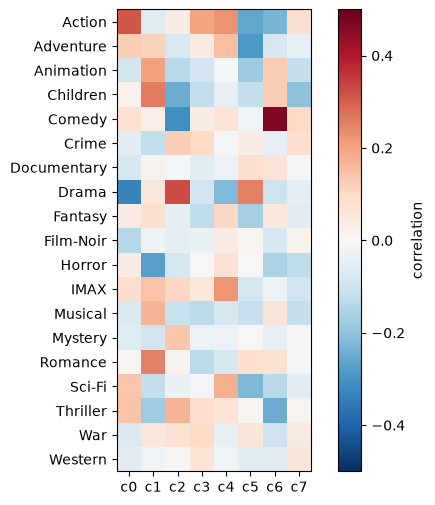

In [15]:
G = pd.get_dummies(items.genres.explode()).groupby(level=0).max().astype(float)
corr = pd.DataFrame({f"c{c}": [np.corrcoef(Z[:, c], G[g])[0, 1] for g in G] for c in range(8)},
                    index=G.columns)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.set_xticks(range(corr.shape[1]), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
fig.colorbar(im, label="correlation")